# A2 — Reconhecimento Semântico em Publicidade Visual com CLIP

**Disciplina:** Visão Computacional com CNNs e Transformers

**Requisitos de execução**
- **GPU:** Colab T4 (Runtime > Change runtime type > T4 GPU). Também roda em CPU, bem mais devagar na indexação das imagens.
- **Memória:** ~6 GB de RAM e ~6 GB de disco (zip de ~1,5 GB e arquivos extraídos).
- **Tempo estimado:** ~10 a 15 minutos (download do dataset, indexação das imagens com o CLIP e download do BERT para a comparação de tokenização). Medido em CPU: indexação das 1.501 imagens em 393,7 s; em GPU T4 essa etapa é mais rápida.
- **Pré-requisito:** montar o Google Drive e disponibilizar o dataset (secret `KAGGLE_API_TOKEN` no Colab ou o `.zip` na pasta do projeto no Drive).
- **Nenhum modelo é treinado:** usamos apenas os embeddings pré-treinados do CLIP (`openai/clip-vit-base-patch32`) e consultas em linguagem natural.
- **Dataset:** [ADS-16 Computational Advertising Dataset](https://www.kaggle.com/datasets/groffo/ads16-dataset) (Roffo e Vinciarelli, 2016).

## Roadmap

1. Ambiente (seed, device, versões)
2. Download e montagem do corpus
3. Modelo CLIP, pré-processamento e indexação das imagens
4. Atividade 2.1: ranking de objetos por frequência semântica
5. Atividade 2.2: busca semântica por consulta textual
6. Análise do alinhamento visual-textual no CLIP
7. Comparação: consulta textual do CLIP vs. tokenização do BERT
8. Referências e declaração de uso de IA

## Ambiente

In [1]:
import os
import glob
import re
import time
import hashlib
import subprocess
import sys
import textwrap
import zipfile
import random

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from PIL import Image
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

if device.type == "cpu":
    print(
        "Aviso: rodando em CPU. Em Runtime > Change runtime type, "
        "selecione GPU (T4) para acelerar a indexação das imagens."
    )

Device: cuda


In [3]:
import transformers
import sklearn

print(f"PyTorch: {torch.__version__}")
print(f"Transformers: {transformers.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")

PyTorch: 2.11.0+cu130
Transformers: 5.18.0
Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.6.1


## Download e Montagem do Corpus

O dataset é baixado pela API do Kaggle. Para isso, adicione nos *Secrets* do Colab (ícone de chave na barra lateral) um segredo chamado `KAGGLE_API_TOKEN` com o token da sua conta Kaggle e ative *Notebook access*.

Alternativa sem token: baixe o `.zip` em https://www.kaggle.com/datasets/groffo/ads16-dataset e coloque-o na pasta `PROJECT_DIR` do Google Drive. A célula de download o extrai automaticamente.

In [4]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/2_clip"
os.makedirs(PROJECT_DIR, exist_ok=True)

Mounted at /content/drive


In [5]:
DATA_DIR = "/content/ads16"

if not os.path.isdir(DATA_DIR):
    try:
        from google.colab import userdata

        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "kaggle"], check=True)
        subprocess.run(
            ["kaggle", "datasets", "download", "-d", "groffo/ads16-dataset", "-p", DATA_DIR, "--unzip"],
            check=True,
        )
    except Exception:
        zip_files = glob.glob(f"{PROJECT_DIR}/*ads16*.zip")
        assert zip_files, "Configure o secret KAGGLE_API_TOKEN ou coloque o .zip do dataset em PROJECT_DIR."
        with zipfile.ZipFile(zip_files[0]) as z:
            z.extractall(DATA_DIR)

print("Dataset pronto em:", DATA_DIR)

Dataset pronto em: /content/ads16


### Organização do dataset e escolha do corpus

O ADS-16 (Roffo e Vinciarelli, 2016) reúne, segundo a documentação do dataset, 300 anúncios reais (formatos Rich Media, Image e Text) em 20 categorias de produto, avaliados por 120 usuários, além de cerca de 1.200 fotos pessoais enviadas por esses usuários. O enunciado fala em 16 categorias e em um corpus de pelo menos 500 imagens. Como o dataset tem menos anúncios do que isso, usamos dois corpora:

- **Corpus principal (anúncios):** todos os anúncios únicos do dataset. É o corpus da busca semântica (2.2) e do ranking principal (2.1).
- **Corpus estendido (anúncios + fotos pessoais):** os anúncios mais as fotos pessoais dos usuários (sem miniaturas), o que passa de 500 imagens. É usado no ranking (2.1) para cumprir o tamanho mínimo pedido e para comparar o que o CLIP encontra em publicidade versus em fotos do cotidiano.

Os arquivos vêm divididos em duas partes (`part1` e `part2`) e podem aparecer duplicados, então as duplicatas são removidas pelo hash MD5 do conteúdo. Se os anúncios estiverem apenas dentro de um `Ads.zip`, ele é extraído automaticamente.

In [6]:
IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".gif", ".webp")


def list_images(base_dir):
    found = []
    for root, _, files in os.walk(base_dir):
        for name in files:
            if name.lower().endswith(IMAGE_EXTENSIONS):
                found.append(os.path.join(root, name))
    return sorted(found)


def has_part(path, part):
    return part.lower() in [p.lower() for p in path.split(os.sep)]


def file_md5(path):
    digest = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def deduplicate(paths):
    seen = set()
    unique = []
    for path in paths:
        key = file_md5(path)
        if key not in seen:
            seen.add(key)
            unique.append(path)
    return unique


def ad_category(path):
    parts = path.split(os.sep)
    lowered = [p.lower() for p in parts]
    last_ads = len(lowered) - 1 - lowered[::-1].index("ads")
    rest = parts[last_ads + 1:]
    return rest[0] if len(rest) > 1 else "sem_categoria"


def photo_info(path):
    parent = os.path.basename(os.path.dirname(path))
    match = re.match(r"^(U\d+).*IM-(POS|NEG)$", parent, flags=re.IGNORECASE)
    if match is None:
        return None
    return match.group(1), match.group(2).upper()


all_images = list_images(DATA_DIR)
ad_candidates = [p for p in all_images if has_part(p, "Ads") and not has_part(p, "Corpus")]

if not ad_candidates:
    for zip_path in sorted(glob.glob(f"{DATA_DIR}/**/Ads.zip", recursive=True)):
        part_name = os.path.basename(os.path.dirname(zip_path))
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(f"/content/ads16_ads/{part_name}/Ads")
    ad_candidates = [p for p in list_images("/content/ads16_ads") if has_part(p, "Ads")]

unique_ads = deduplicate(ad_candidates)
assert len(unique_ads) > 0, "Nenhum anúncio encontrado no dataset."

ads_df = pd.DataFrame({"path": unique_ads})
ads_df["category"] = ads_df["path"].map(ad_category)
ads_df["source"] = "anúncio"

photo_candidates = [p for p in all_images if has_part(p, "Corpus") and photo_info(p) is not None]
photo_originals = [p for p in photo_candidates if "_th_" not in os.path.basename(p)]
unique_photos = deduplicate(photo_originals)

photos_df = pd.DataFrame({"path": unique_photos})
photos_df["category"] = "foto pessoal"
photos_df["source"] = "foto pessoal"

print(f"Anúncios: {len(ad_candidates)} arquivos encontrados, {len(ads_df)} únicos, {ads_df['category'].nunique()} categorias")
print(f"Fotos pessoais: {len(photo_candidates)} arquivos, {len(photo_originals)} sem miniaturas, {len(photos_df)} únicas")

Anúncios: 301 arquivos encontrados, 301 únicos, 20 categorias
Fotos pessoais: 2396 arquivos, 1223 sem miniaturas, 1200 únicas


In [7]:
def inspect_image(path):
    try:
        with Image.open(path) as img:
            img.verify()
        with Image.open(path) as img:
            return img.size
    except Exception:
        return None


corpus_df = pd.concat([ads_df, photos_df], ignore_index=True)

sizes = [inspect_image(p) for p in corpus_df["path"]]
valid = np.array([s is not None for s in sizes])
corpus_df["width"] = [s[0] if s else 0 for s in sizes]
corpus_df["height"] = [s[1] if s else 0 for s in sizes]

print(f"Imagens inválidas descartadas: {int((~valid).sum())}")

corpus_df = corpus_df[valid].reset_index(drop=True)
corpus_df["aspect"] = corpus_df["width"] / corpus_df["height"]

ads_rows = np.flatnonzero(corpus_df["source"] == "anúncio")
photos_rows = np.flatnonzero(corpus_df["source"] == "foto pessoal")
ads_df = corpus_df.iloc[ads_rows]
photos_df = corpus_df.iloc[photos_rows]

print(f"Corpus principal (anúncios): {len(ads_rows)} imagens")
print(f"Corpus estendido (anúncios + fotos pessoais): {len(corpus_df)} imagens")
print()
print("Proporção largura/altura dos anúncios")
print(ads_df["aspect"].describe().round(2))
extreme = ((ads_df["aspect"] > 1.5) | (ads_df["aspect"] < 1 / 1.5)).mean()
print(f"\nAnúncios com proporção fora do intervalo 2:3 a 3:2: {extreme:.1%}")

Imagens inválidas descartadas: 0
Corpus principal (anúncios): 301 imagens
Corpus estendido (anúncios + fotos pessoais): 1501 imagens

Proporção largura/altura dos anúncios
count    301.00
mean       1.00
std        0.02
min        1.00
25%        1.00
50%        1.00
75%        1.00
max        1.30
Name: aspect, dtype: float64

Anúncios com proporção fora do intervalo 2:3 a 3:2: 0.0%


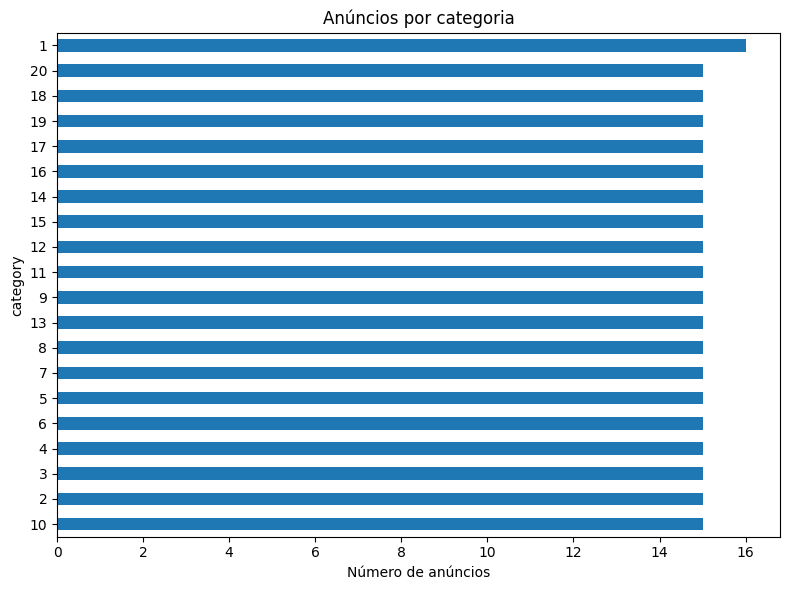

category
1     16
10    15
11    15
12    15
13    15
14    15
15    15
16    15
17    15
18    15
19    15
2     15
20    15
3     15
4     15
5     15
6     15
7     15
8     15
9     15


In [8]:
category_counts = ads_df["category"].value_counts().sort_values()

category_counts.plot(kind="barh", figsize=(8, 6))
plt.xlabel("Número de anúncios")
plt.title("Anúncios por categoria")
plt.tight_layout()
plt.show()

print(category_counts.sort_index().to_string())

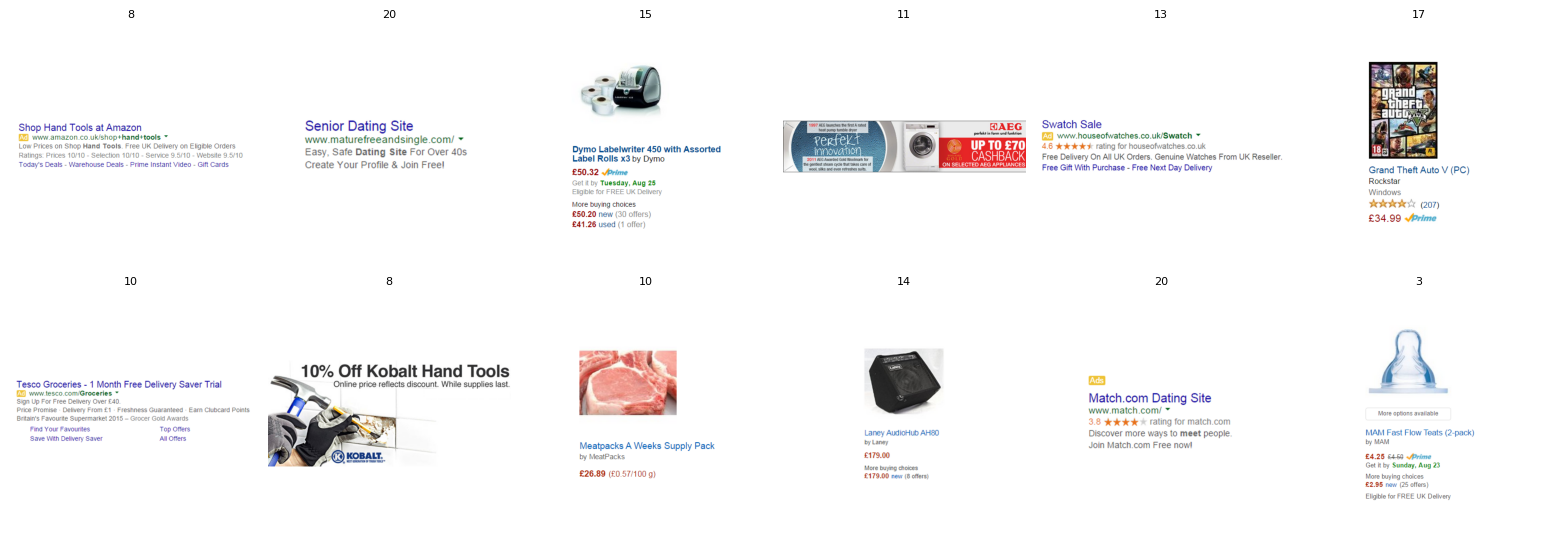

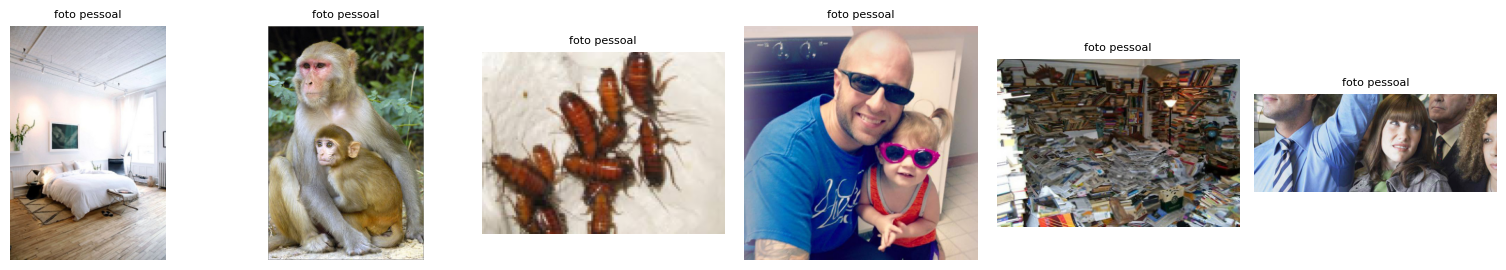

In [9]:
def load_rgb(path):
    img = Image.open(path)
    if img.mode in ("RGBA", "LA") or (img.mode == "P" and "transparency" in img.info):
        img = img.convert("RGBA")
        background = Image.new("RGB", img.size, (255, 255, 255))
        background.paste(img, mask=img.split()[-1])
        return background
    return img.convert("RGB")


def pad_to_square(img):
    width, height = img.size
    side = max(width, height)
    canvas = Image.new("RGB", (side, side), (255, 255, 255))
    canvas.paste(img, ((side - width) // 2, (side - height) // 2))
    return canvas


def show_grid(rows, titles, n_cols, cell_size=(3, 3)):
    n_rows = int(np.ceil(len(rows) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(cell_size[0] * n_cols, cell_size[1] * n_rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, row, title in zip(axes, rows, titles):
        ax.imshow(load_rgb(corpus_df.loc[row, "path"]))
        ax.set_title(textwrap.fill(title, 24), fontsize=8)
    plt.tight_layout()
    plt.show()


rng = np.random.default_rng(SEED)
ad_sample = rng.choice(ads_rows, size=min(12, len(ads_rows)), replace=False)
show_grid(ad_sample, [corpus_df.loc[i, "category"] for i in ad_sample], n_cols=6, cell_size=(2.6, 2.8))

photo_sample = rng.choice(photos_rows, size=min(6, len(photos_rows)), replace=False)
show_grid(photo_sample, ["foto pessoal"] * len(photo_sample), n_cols=6, cell_size=(2.6, 2.8))

## Modelo CLIP, Pré-processamento e Indexação das Imagens

Carregamos o checkpoint oficial `openai/clip-vit-base-patch32` via Hugging Face. O CLIP é formado por duas torres: um Vision Transformer (ViT-B/32), que divide a imagem em patches de 32×32 pixels, e um Transformer de texto. Cada torre termina em uma projeção linear para o mesmo espaço de 512 dimensões, e os dois vetores são normalizados (L2) antes de qualquer comparação. A similaridade entre uma imagem e um texto é o cosseno entre seus vetores.

In [10]:
from transformers import CLIPModel, CLIPProcessor

MODEL_NAME = "openai/clip-vit-base-patch32"

processor = CLIPProcessor.from_pretrained(MODEL_NAME)
model = CLIPModel.from_pretrained(MODEL_NAME).to(device)
model.eval()

total_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Parâmetros totais: {total_params:.1f} milhões")
print(f"Projeção visual: {model.visual_projection.in_features} -> {model.visual_projection.out_features}")
print(f"Projeção textual: {model.text_projection.in_features} -> {model.text_projection.out_features}")
print(f"Fator de escala aprendido (exp(logit_scale)): {model.logit_scale.exp().item():.2f}")

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Parâmetros totais: 151.3 milhões
Projeção visual: 768 -> 512
Projeção textual: 512 -> 512


model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Fator de escala aprendido (exp(logit_scale)): 100.00


### Pré-processamento das imagens

O `CLIPProcessor` redimensiona o lado menor da imagem para 224 pixels e recorta o centro de 224×224. Anúncios têm proporções muito variadas (banners largos, imagens altas, anúncios só de texto), e o recorte central descartaria as bordas, onde costumam ficar logotipos, preços e chamadas. Por isso, antes do processador, cada imagem com transparência é composta sobre fundo branco e depois preenchida com branco até ficar quadrada, preservando todo o conteúdo. A célula de tamanhos acima mostra a fração de anúncios com proporção distante de 1:1, que é o caso em que essa escolha importa.

As imagens são codificadas uma única vez e os vetores ficam guardados em memória (indexação offline). Toda consulta posterior só precisa codificar o texto e calcular produtos escalares.

In [11]:
def to_feature_tensor(output, names):
    if isinstance(output, torch.Tensor):
        return output
    for name in names:
        value = getattr(output, name, None)
        if value is not None:
            return value
    return output[0]


class AdImageDataset(Dataset):

    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        try:
            img = pad_to_square(load_rgb(self.paths[idx]))
        except Exception:
            img = Image.new("RGB", (224, 224), (255, 255, 255))
        return processor.image_processor(images=img, return_tensors="pt")["pixel_values"][0]


@torch.no_grad()
def encode_images(paths, batch_size=64):
    loader = DataLoader(AdImageDataset(paths), batch_size=batch_size, shuffle=False, num_workers=2)
    chunks = []
    for batch in loader:
        output = model.get_image_features(pixel_values=batch.to(device))
        features = to_feature_tensor(output, ("image_embeds", "pooler_output"))
        if features.shape[-1] != model.config.projection_dim:
            features = model.visual_projection(features)
        chunks.append(F.normalize(features, dim=-1).cpu())
    return torch.cat(chunks)


@torch.no_grad()
def encode_texts(texts, batch_size=64):
    chunks = []
    for start in range(0, len(texts), batch_size):
        inputs = processor(
            text=list(texts[start:start + batch_size]),
            return_tensors="pt",
            padding=True,
            truncation=True,
        ).to(device)
        output = model.get_text_features(**inputs)
        features = to_feature_tensor(output, ("text_embeds", "pooler_output"))
        if features.shape[-1] != model.config.projection_dim:
            features = model.text_projection(features)
        chunks.append(F.normalize(features, dim=-1).cpu())
    return torch.cat(chunks)


def encode_concepts(concepts, templates):
    embeddings = []
    for concept in concepts:
        prompts = [template.format(c=concept) for template in templates]
        mean_embedding = encode_texts(prompts).mean(dim=0)
        embeddings.append(F.normalize(mean_embedding, dim=0))
    return torch.stack(embeddings)

In [12]:
start = time.perf_counter()
image_embeddings = encode_images(corpus_df["path"].tolist())
elapsed = time.perf_counter() - start

ads_embeddings = image_embeddings[ads_rows]
photos_embeddings = image_embeddings[photos_rows]

print(f"Imagens indexadas: {image_embeddings.shape[0]} em {elapsed:.1f} s")
print(f"Dimensão dos embeddings: {image_embeddings.shape[1]}")
print(f"Norma média dos vetores: {image_embeddings.norm(dim=-1).mean().item():.4f}")

Imagens indexadas: 1501 em 35.0 s
Dimensão dos embeddings: 512
Norma média dos vetores: 1.0000


## Atividade 2.1: Ranking de Objetos por Frequência Semântica

**Método.** Definimos 32 descrições de objetos e conceitos relevantes para publicidade (pessoas, produtos de consumo, cenários, elementos gráficos). Cada descrição é codificada com um *ensemble* de três templates (`an advertisement showing {c}.`, `a photo of {c}.`, `an image containing {c}.`), e o vetor médio normalizado representa o conceito. Para cada imagem, calculamos o cosseno com os 32 conceitos.

**Definição de presença.** Os cossenos do CLIP não são probabilidades calibradas: ficam concentrados numa faixa estreita (em torno de 0,1 a 0,35) por causa do *modality gap* entre os espaços de imagem e texto, então um corte absoluto (como 0,5) não faz sentido e um valor como 0,25 seria arbitrário. Por isso o threshold é definido a partir da própria distribuição: um objeto é considerado presente em uma imagem quando o cosseno é maior ou igual a **μ + 1σ**, onde μ e σ são a média e o desvio padrão de todos os pares (imagem, conceito) do corpus principal. A justificativa é que um anúncio mostra poucos dos 32 conceitos, então a maior parte dos pares corresponde a "ausente" e forma o corpo da distribuição; um score um desvio padrão acima dele é um desvio estatisticamente saliente. O mesmo threshold é aplicado aos demais corpora, para que as frequências sejam comparáveis.

Como o threshold é uma escolha, testamos a sensibilidade do ranking a ele (μ + 0,5σ, μ + 1σ, μ + 1,5σ e a regra alternativa "top-3 conceitos por imagem").

In [13]:
OBJECTS = [
    ("pessoa", "a person"),
    ("grupo de pessoas", "a group of people"),
    ("mulher", "a woman"),
    ("homem", "a man"),
    ("criança ou bebê", "a child or a baby"),
    ("carro", "a car"),
    ("alimento", "food"),
    ("bebida", "a drink"),
    ("aparelho eletrônico", "an electronic device"),
    ("notebook", "a laptop computer"),
    ("celular", "a smartphone"),
    ("livro", "a book"),
    ("roupa", "clothing"),
    ("calçado", "shoes"),
    ("joia ou relógio", "jewelry or a watch"),
    ("móvel", "furniture"),
    ("animal de estimação", "a pet animal"),
    ("paisagem ao ar livre", "outdoor scenery"),
    ("edifício ou casa", "a building or a house"),
    ("texto e logotipo", "text and a logo"),
    ("eletrodoméstico", "a home appliance"),
    ("brinquedo", "a toy"),
    ("equipamento esportivo", "sports equipment"),
    ("cosméticos", "cosmetics and beauty products"),
    ("produto de saúde", "a health or medical product"),
    ("instrumento musical", "a musical instrument"),
    ("bolsa ou mala", "a bag or luggage"),
    ("ferramenta", "a tool"),
    ("videogame", "a video game"),
    ("filme ou música", "a movie or a music album"),
    ("preço ou desconto", "a price tag or a discount"),
    ("ilustração ou desenho", "a cartoon or an illustration"),
]

OBJECT_LABELS = [label for label, _ in OBJECTS]
OBJECT_PROMPTS = [prompt for _, prompt in OBJECTS]

TEMPLATES = [
    "an advertisement showing {c}.",
    "a photo of {c}.",
    "an image containing {c}.",
]

concept_embeddings = encode_concepts(OBJECT_PROMPTS, TEMPLATES)

scores_all = image_embeddings @ concept_embeddings.T
scores_ads = scores_all[ads_rows]
scores_photos = scores_all[photos_rows]

print(f"Conceitos: {len(OBJECTS)}")
print(f"Matriz de scores (corpus estendido): {tuple(scores_all.shape)}")

Conceitos: 32
Matriz de scores (corpus estendido): (1501, 32)


Média dos cossenos (anúncios x conceitos): 0.2096
Desvio padrão: 0.0252
Threshold de presença (μ + 1σ): 0.2348


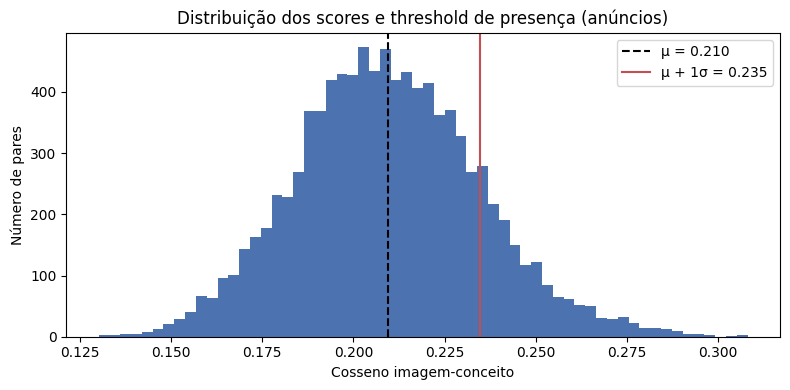

In [14]:
mu = scores_ads.mean().item()
sigma = scores_ads.std().item()
tau = mu + 1.0 * sigma

print(f"Média dos cossenos (anúncios x conceitos): {mu:.4f}")
print(f"Desvio padrão: {sigma:.4f}")
print(f"Threshold de presença (μ + 1σ): {tau:.4f}")

plt.figure(figsize=(8, 4))
plt.hist(scores_ads.flatten().numpy(), bins=60, color="#4C72B0")
plt.axvline(mu, color="black", linestyle="--", label=f"μ = {mu:.3f}")
plt.axvline(tau, color="#C44E52", linestyle="-", label=f"μ + 1σ = {tau:.3f}")
plt.xlabel("Cosseno imagem-conceito")
plt.ylabel("Número de pares")
plt.title("Distribuição dos scores e threshold de presença (anúncios)")
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
def presence_by_threshold(scores, threshold):
    return scores >= threshold


def presence_by_topk(scores, k=3):
    top_indices = scores.topk(k, dim=1).indices
    presence = torch.zeros_like(scores, dtype=torch.bool)
    presence.scatter_(1, top_indices, True)
    return presence


def rank_objects(scores, presence, labels):
    frequency = presence.float().mean(dim=0)
    mean_score = scores.mean(dim=0)
    mean_when_present = (scores * presence).sum(dim=0) / presence.sum(dim=0).clamp(min=1)
    table = pd.DataFrame({
        "objeto": labels,
        "frequência (%)": (frequency * 100).numpy(),
        "imagens com o objeto": presence.sum(dim=0).numpy(),
        "score médio": mean_score.numpy(),
        "score médio quando presente": mean_when_present.numpy(),
    })
    table = table.sort_values(["frequência (%)", "score médio"], ascending=False).reset_index(drop=True)
    table.index = table.index + 1
    table.index.name = "posição"
    return table


presence_ads = presence_by_threshold(scores_ads, tau)
ranking_ads = rank_objects(scores_ads, presence_ads, OBJECT_LABELS)

print(f"Ranking de objetos no corpus principal ({len(ads_rows)} anúncios), presença = cosseno >= {tau:.3f}")
display(ranking_ads.round(3))

Ranking de objetos no corpus principal (301 anúncios), presença = cosseno >= 0.235


,objeto,frequência (%),imagens com o objeto,score médio,score médio quando presente
posição,,,,,
1,preço ou desconto,78.072998,235,0.251,0.259
2,texto e logotipo,51.827000,156,0.233,0.250
3,ferramenta,37.874001,114,0.228,0.247
4,eletrodoméstico,33.555000,101,0.224,0.247
5,produto de saúde,31.893999,96,0.224,0.249
6,brinquedo,29.236000,88,0.225,0.247
7,videogame,28.570999,86,0.222,0.249
8,aparelho eletrônico,13.953000,42,0.215,0.244
9,livro,13.953000,42,0.214,0.242


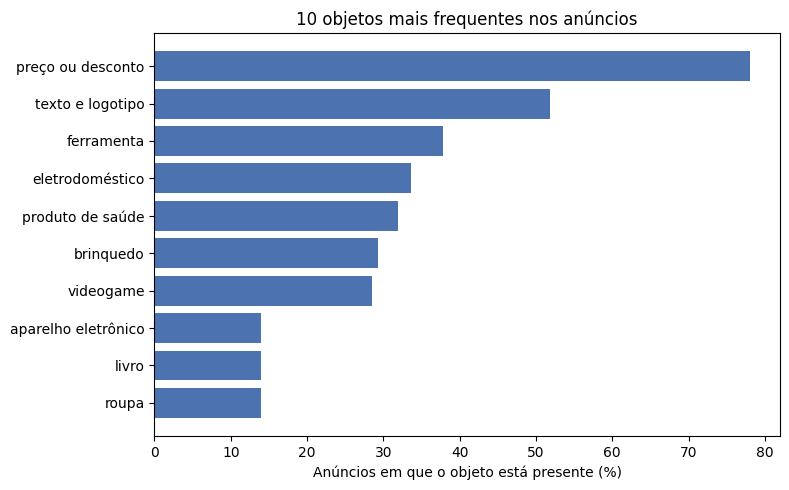

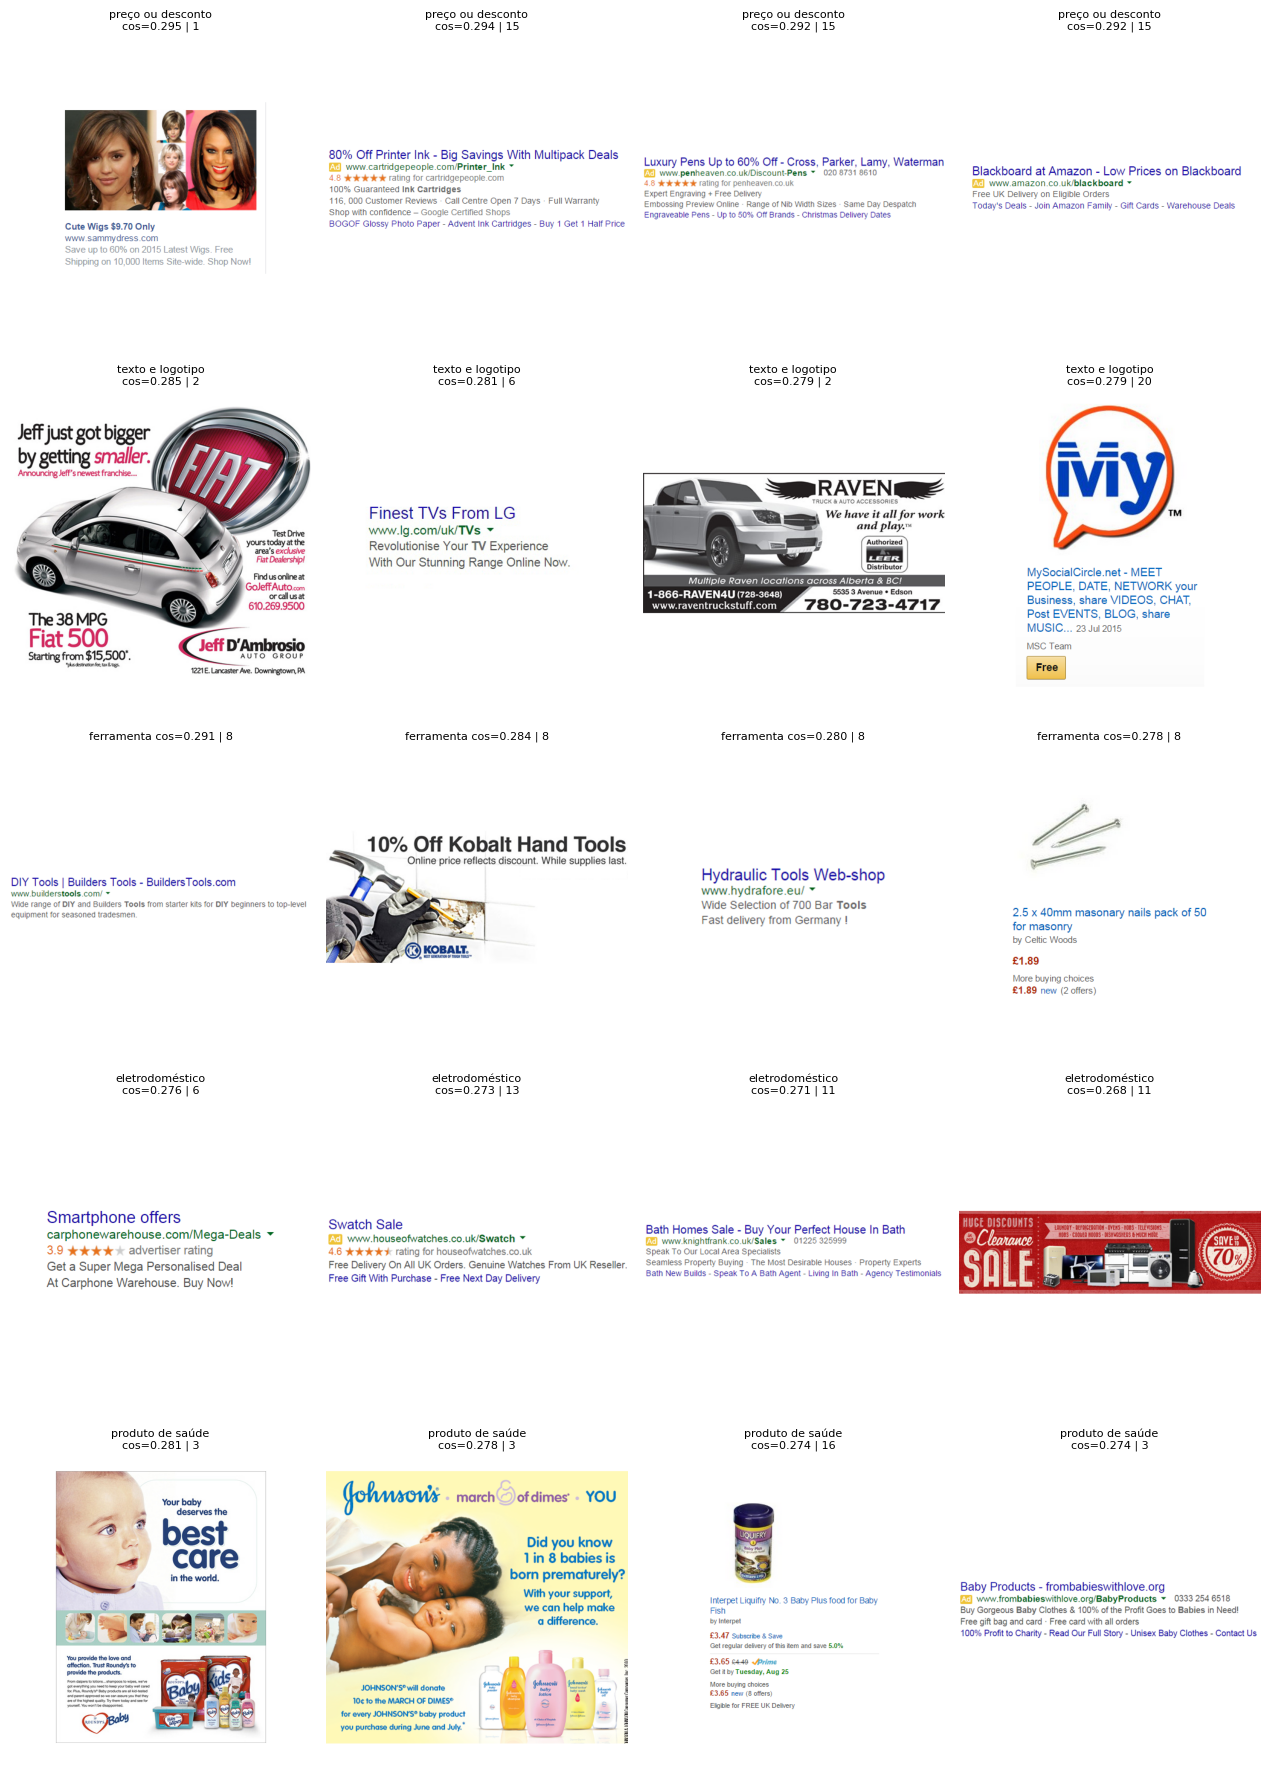

In [16]:
top5_names = ranking_ads["objeto"].head(5).tolist()

top10 = ranking_ads.head(10).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top10["objeto"], top10["frequência (%)"], color="#4C72B0")
plt.xlabel("Anúncios em que o objeto está presente (%)")
plt.title("10 objetos mais frequentes nos anúncios")
plt.tight_layout()
plt.show()

rows = []
titles = []
for name in top5_names:
    column = OBJECT_LABELS.index(name)
    best_scores, best_positions = scores_ads[:, column].topk(4)
    for score, position in zip(best_scores.tolist(), best_positions.tolist()):
        row = ads_rows[position]
        rows.append(row)
        titles.append(f"{name}\ncos={score:.3f} | {corpus_df.loc[row, 'category']}")

show_grid(rows, titles, n_cols=4, cell_size=(3.2, 3.6))

In [17]:
rules = {
    "μ + 0,5σ": presence_by_threshold(scores_ads, mu + 0.5 * sigma),
    "μ + 1σ (regra principal)": presence_by_threshold(scores_ads, mu + 1.0 * sigma),
    "μ + 1,5σ": presence_by_threshold(scores_ads, mu + 1.5 * sigma),
    "top-3 conceitos por imagem": presence_by_topk(scores_ads, 3),
}

main_top5 = set(top5_names)
sensitivity_rows = []
for rule_name, presence in rules.items():
    ranking = rank_objects(scores_ads, presence, OBJECT_LABELS)
    top5 = ranking["objeto"].head(5).tolist()
    sensitivity_rows.append({
        "regra de presença": rule_name,
        "top 5": ", ".join(top5),
        "objetos do top 5 em comum com a regra principal": len(main_top5 & set(top5)),
        "objetos detectados por imagem (média)": round(presence.float().sum(dim=1).mean().item(), 2),
    })

display(pd.DataFrame(sensitivity_rows))

,regra de presença,top 5,objetos do top 5 em comum com a regra principal,objetos detectados por imagem (média)
0,"μ + 0,5σ","preço ou desconto, texto e logotipo, ferrament...",4,9.60
1,μ + 1σ (regra principal),"preço ou desconto, texto e logotipo, ferrament...",5,4.93
2,"μ + 1,5σ","preço ou desconto, texto e logotipo, produto d...",5,2.22
3,top-3 conceitos por imagem,"preço ou desconto, texto e logotipo, produto d...",3,3.00


### Análise da atividade 2.1

**Ranking.** No corpus de anúncios, os objetos mais frequentes (cosseno ≥ 0,235) são *preço ou desconto* (78,1%; 235 de 301 anúncios), *texto e logotipo* (51,8%), *ferramenta* (37,9%), *eletrodoméstico* (33,6%) e *produto de saúde* (31,9%). O resultado descreve bem o gênero: anúncios online são dominados por texto promocional, marca e produto, e raramente mostram pessoas (*pessoa* aparece em apenas 7,3% dos anúncios).

**Confirmação visual dos 5 principais.** Os exemplos de maior score confirmam as três primeiras categorias: *preço ou desconto* recupera anúncios com "up to 60% off", "80% off" e "low prices"; *texto e logotipo* recupera anúncios com marca e texto em destaque (Fiat 500, LG, Raven); *ferramenta* recupera apenas anúncios de ferramentas (Kobalt, builders tools, hydraulic tools, pregos), todos da categoria 8. Já *eletrodoméstico* mostra um desvio: três dos quatro exemplos são anúncios apenas de texto ("Smartphone offers", "Swatch Sale", "Bath Homes Sale"), e só o último mostra eletrodomésticos de fato. O CLIP reage ao **estilo do anúncio** (texto de promoção) tanto quanto ao objeto citado, e *produto de saúde* captura sobretudo produtos de bebê e cuidado infantil (categoria 3), uma aproximação semântica razoável, mas não literal.

**Corpus estendido.** Ao incluir as 1.200 fotos pessoais, *pessoa* sobe para o 3º lugar (18,7%) e *animal de estimação* entra no top 8 (13,2%), enquanto *preço ou desconto* cai para 22,7%. O contraste confirma que o ranking reflete o conteúdo do corpus: anúncios giram em torno de produto e texto; fotos pessoais, em torno de pessoas e animais.

**Sensibilidade ao threshold.** Com μ + 0,5σ, o top 5 compartilha 4 objetos com a regra principal e cada imagem tem em média 9,6 objetos detectados (permissivo demais para um anúncio); com μ + 1,5σ, compartilha os 5, com 2,2 objetos por imagem. A regra alternativa de top-3 por imagem mantém apenas 3 dos 5. Portanto o ranking é estável em torno do threshold escolhido (μ + 1σ, ~4,9 objetos por imagem), e os primeiros colocados (*preço* e *texto e logotipo*) não dependem da regra.

**Limitações.** (i) A lista de 32 conceitos define o que pode aparecer no ranking. (ii) Conceitos correlacionados (por exemplo, *preço* e *texto*) se sobrepõem, porque anúncios com muito texto pontuam alto em vários conceitos. (iii) Um cosseno acima do limiar indica proximidade semântica, não prova de presença do objeto.

Ranking no corpus estendido (1501 imagens), mesmo threshold 0.235


,objeto,frequência (%),imagens com o objeto,score médio,score médio quando presente
posição,,,,,
1,preço ou desconto,22.718000,341,0.222,0.254
2,texto e logotipo,19.787001,297,0.216,0.248
3,pessoa,18.653999,280,0.218,0.245
4,ferramenta,17.322001,260,0.217,0.245
5,produto de saúde,17.188999,258,0.213,0.248
6,brinquedo,16.789000,252,0.216,0.246
7,videogame,13.924000,209,0.215,0.247
8,animal de estimação,13.191000,198,0.207,0.256
9,roupa,11.859000,178,0.212,0.247


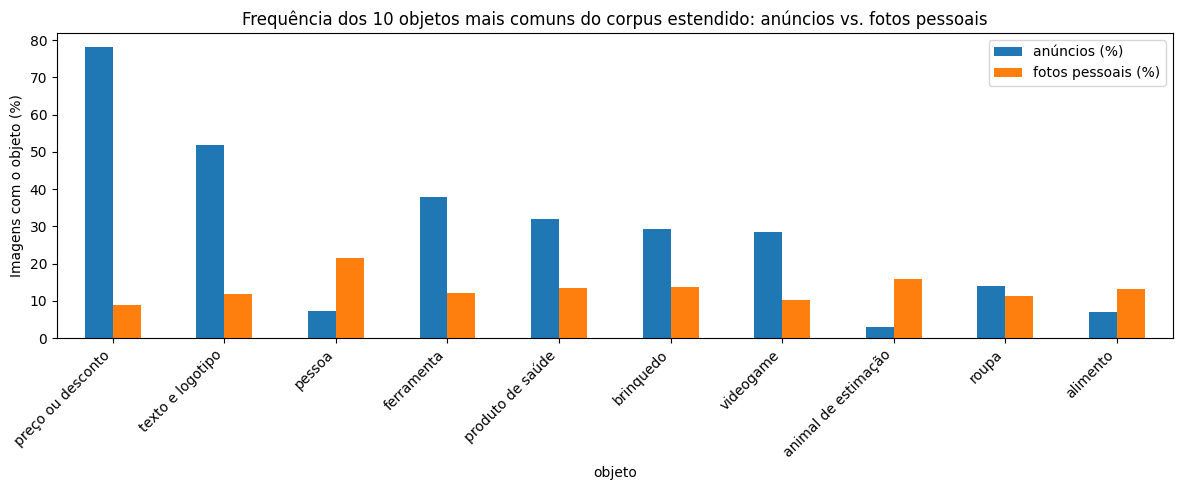

In [18]:
presence_all = presence_by_threshold(scores_all, tau)
ranking_all = rank_objects(scores_all, presence_all, OBJECT_LABELS)

print(f"Ranking no corpus estendido ({len(corpus_df)} imagens), mesmo threshold {tau:.3f}")
display(ranking_all.head(10).round(3))

comparison = pd.DataFrame({
    "objeto": OBJECT_LABELS,
    "anúncios (%)": presence_by_threshold(scores_ads, tau).float().mean(dim=0).numpy() * 100,
    "fotos pessoais (%)": presence_by_threshold(scores_photos, tau).float().mean(dim=0).numpy() * 100,
    "corpus estendido (%)": presence_all.float().mean(dim=0).numpy() * 100,
}).set_index("objeto")

top_extended = comparison.sort_values("corpus estendido (%)", ascending=False).head(10)
top_extended[["anúncios (%)", "fotos pessoais (%)"]].plot(kind="bar", figsize=(12, 5))
plt.ylabel("Imagens com o objeto (%)")
plt.title("Frequência dos 10 objetos mais comuns do corpus estendido: anúncios vs. fotos pessoais")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Atividade 2.2: Busca Semântica por Consulta Textual

**Método.** Com as imagens já indexadas, a busca se resume a codificar a consulta, calcular o cosseno contra todos os vetores do corpus principal (anúncios) e retornar as 5 imagens mais similares. As 10 consultas abaixo variam em especificidade (de genérica a específica) e em natureza (de conceitos concretos a ideias abstratas e a propriedades de layout), incluindo conceitos que provavelmente quase não aparecem em anúncios, para observar como o modelo se comporta quando o conceito está ausente.

Para cada consulta, além das imagens, registramos três medidas: o cosseno do 1º colocado, a média do top-5 e o *z-score* do 1º colocado em relação à distribuição de scores da consulta em todo o corpus (quantos desvios padrão acima da média o melhor resultado está).

In [19]:
QUERIES = [
    ("a person", "genérica, concreta"),
    ("food", "genérica, concreta"),
    ("a woman smiling while holding a smartphone", "específica, concreta"),
    ("a red sports car driving on a road", "específica, concreta"),
    ("a dog playing outdoors", "específica, concreta"),
    ("a book cover with a title", "específica, formato"),
    ("text only advertisement without photographs", "layout"),
    ("big discount, sale and low prices", "abstrata, promoção"),
    ("luxury and elegance", "abstrata"),
    ("happiness and family time", "abstrata, emocional"),
]

ads_paths = ads_df["path"].tolist()
ads_categories = ads_df["category"].tolist()


def semantic_search(query, kind, top_k=5):
    query_embedding = encode_texts([query])[0]
    similarities = ads_embeddings @ query_embedding
    top_scores, top_indices = similarities.topk(top_k)

    fig, axes = plt.subplots(1, top_k, figsize=(3.1 * top_k, 3.9))
    for rank, (position, score, ax) in enumerate(zip(top_indices.tolist(), top_scores.tolist(), axes), start=1):
        ax.imshow(load_rgb(ads_paths[position]))
        ax.set_title(textwrap.fill(f"#{rank}  cos={score:.3f}\n{ads_categories[position]}", 24), fontsize=9)
        ax.axis("off")
    fig.suptitle(f'Consulta ({kind}): "{query}"', fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

    z_top1 = (top_scores[0] - similarities.mean()) / similarities.std()
    return {
        "consulta": query,
        "tipo": kind,
        "cosseno do 1º": round(top_scores[0].item(), 3),
        "média do top-5": round(top_scores.mean().item(), 3),
        "média do corpus": round(similarities.mean().item(), 3),
        "z-score do 1º": round(z_top1.item(), 2),
        "categorias do top-5": ", ".join(ads_categories[p] for p in top_indices.tolist()),
    }


search_summary = [semantic_search(query, kind) for query, kind in QUERIES]

Output hidden; open in https://colab.research.google.com to view.

In [20]:
summary_df = pd.DataFrame(search_summary)
summary_df.index = summary_df.index + 1
summary_df.index.name = "consulta nº"
display(summary_df)

,consulta,tipo,cosseno do 1º,média do top-5,média do corpus,z-score do 1º,categorias do top-5
consulta nº,,,,,,,
1,a person,"genérica, concreta",0.230,0.225,0.177,3.00,"20, 20, 18, 1, 19"
2,food,"genérica, concreta",0.261,0.248,0.184,3.71,"16, 16, 10, 9, 10"
3,a woman smiling while holding a smartphone,"específica, concreta",0.248,0.231,0.152,3.15,"6, 6, 6, 20, 20"
4,a red sports car driving on a road,"específica, concreta",0.230,0.218,0.142,3.04,"14, 2, 2, 2, 2"
5,a dog playing outdoors,"específica, concreta",0.226,0.216,0.140,3.76,"16, 16, 16, 10, 16"
6,a book cover with a title,"específica, formato",0.255,0.249,0.200,2.40,"16, 9, 5, 18, 3"
7,text only advertisement without photographs,layout,0.293,0.289,0.243,1.99,"6, 1, 11, 13, 19"
8,"big discount, sale and low prices","abstrata, promoção",0.285,0.283,0.243,2.61,"11, 14, 15, 13, 2"
9,luxury and elegance,abstrata,0.223,0.220,0.181,2.67,"15, 13, 6, 15, 1"


### Análise da atividade 2.2

| # | Consulta | z-score do 1º | O que o modelo recuperou |
|---|---|---|---|
| 1 | a person | 3,00 | Anúncios de sites de encontros (Badoo, Latin Women Dating), um tênis com atleta e um modelo; interpreta "pessoa" como relacionamento social, em boa parte pelo **texto** da imagem |
| 2 | food | 3,71 | Ração para pets (2), pizza, vegetais e snacks: recuperação correta, inclusive a ração, que também é "food" |
| 3 | a woman smiling while holding a smartphone | 3,15 | Capta o objeto (anúncio de smartphone, tablet, app Tinder), mas não a cena: nenhuma mulher sorrindo com celular |
| 4 | a red sports car driving on a road | 3,04 | Retorna uma pandeireta **vermelha** e itens de autopeças e acessórios; capta cor e tema "carro", mas não há carro esportivo no corpus |
| 5 | a dog playing outdoors | 3,76 | Pet shop, ração e um anúncio da Pedigree com cachorro; em 4º lugar aparece o anúncio de **hot dog** (ambiguidade lexical) |
| 6 | a book cover with a title | 2,40 | Falha: sela, sementes, mochila e produtos de bebê; só o 3º (livraria Oxfam) é relevante, e é um anúncio de texto |
| 7 | text only advertisement without photographs | 1,99 | Sucesso: os 5 resultados são anúncios só de texto |
| 8 | big discount, sale and low prices | 2,61 | Sucesso: 4 de 5 são banners de liquidação ("Winter Sale 15% off", "Warehouse Sale 86%", "flat 10%") |
| 9 | luxury and elegance | 2,67 | Sucesso: joalheria, canetas de luxo, TV de £34.999, óculos Gucci e cadeira de couro |
| 10 | happiness and family time | 3,43 | Bebê com mãe, campanha infantil e casal (eHarmony); erros: ferramentas hidráulicas e banner da Lego |

**Concreto e genérico (1, 2).** Funcionam melhor quando o conceito é um tema forte do corpus (comida). "A person" é interpretado de forma inesperada: o CLIP lê o texto "Meet New People", "Dating Site", e relaciona pessoa a encontros.

**Concreto e específico (3, 4, 5).** Combinações de atributos ("mulher sorrindo segurando smartphone", "carro esportivo vermelho") são recuperadas por **partes**: o modelo acerta o substantivo dominante e perde a relação entre os atributos e a cena. Como o corpus não contém essas cenas, o modelo devolve o mais próximo (pandeireta vermelha, autopeças) com cosseno e z-score parecidos com os de buscas bem-sucedidas, de modo que **um score alto não indica que o conteúdo existe**. No caso do cachorro, a confusão com *hot dog* mostra o viés lexical herdado dos pares imagem-texto da web.

**Formato e layout (6, 7).** "Anúncio apenas de texto" funciona porque o CLIP lê e reconhece o estilo visual de um anúncio de busca patrocinada. Já "capa de livro com título" falha, porque o corpus não tem capas de livro. O z-score do caso 7 é o menor (1,99), embora o resultado seja o melhor: muitos anúncios de texto compartilham scores altos, o que eleva o desvio padrão da distribuição. Logo, o z-score mede quão **isolado** é o melhor resultado, não a qualidade da busca.

**Abstrato (8, 9, 10).** São os casos mais interessantes: "sale", "luxury" e "family" não têm um objeto físico, e mesmo assim o modelo recupera banners de liquidação, marcas de luxo e cenas materno-infantis. O vocabulário aberto do pré-treinamento contrastivo captura conceitos associados a contextos visuais e textuais recorrentes. O ponto fraco é o ruído nas posições inferiores (ferramentas hidráulicas e Lego em "família e felicidade").

**Conclusão.** Das 10 consultas, 5 retornaram resultados majoritariamente corretos (2, 7, 8, 9 e 10), 4 foram parcialmente corretas (1, 3, 4 e 5) e 1 falhou (6). O CLIP funciona como busca semântica de vocabulário aberto sem treino, mas combina conceitos de forma superficial, depende do texto presente nas imagens e sempre devolve algo, mesmo quando o conteúdo procurado não existe.

## Análise do Alinhamento Visual-Textual no CLIP

**Por que o pré-treinamento contrastivo habilita recuperação semântica sem treino supervisionado.** O CLIP (Radford et al., 2021) foi treinado com cerca de 400 milhões de pares imagem-texto coletados da web. Em cada passo, um lote de N pares gera uma matriz N×N de similaridades (cosseno multiplicado por um fator de escala aprendido). A perda é uma entropia cruzada simétrica: para cada imagem, o texto correto (a diagonal) deve ganhar dos outros N−1 textos do lote, e para cada texto, a imagem correta deve ganhar das outras N−1 imagens. Os pares incorretos do próprio lote funcionam como negativos, sem nenhum rótulo manual.

Duas consequências explicam o que fizemos neste notebook:

1. **Espaço compartilhado.** Como as duas torres são otimizadas para que pares correspondentes tenham cosseno alto e pares não correspondentes tenham cosseno baixo, imagem e texto passam a viver no mesmo espaço de 512 dimensões, onde proximidade significa relação semântica, independentemente da modalidade. Um texto vira um "protótipo" que pode ser comparado a qualquer imagem por um produto escalar.
2. **Vocabulário aberto.** O sinal de supervisão é a linguagem natural, não um conjunto fixo de classes. Por isso uma descrição nova, como "luxury and elegance", pode ser codificada em tempo de inferência e comparada às imagens sem nenhum treinamento adicional. O ranking de objetos (2.1) e a busca (2.2) são exatamente isso: vetores de texto contra vetores de imagem pré-computados.

**Limites.** Os cossenos absolutos são baixos e pouco calibrados (por isso o threshold relativo da seção 2.1), o modelo tem dificuldade com contagem, negação e relações espaciais, e herda os vieses dos dados da web. Em anúncios, há ainda muito texto embutido na imagem, que o CLIP lê só parcialmente.

As células a seguir medem empiricamente esse alinhamento no ADS-16.

Classificação zero-shot por categoria de produto (20 categorias, sem nenhum treino)
  Acurácia top-1: 4.3%  (acaso: 5.0%)
  Acurácia top-3: 15.3%
  Cosseno médio com a própria categoria: 0.2243
  Cosseno médio com as outras categorias: 0.2243


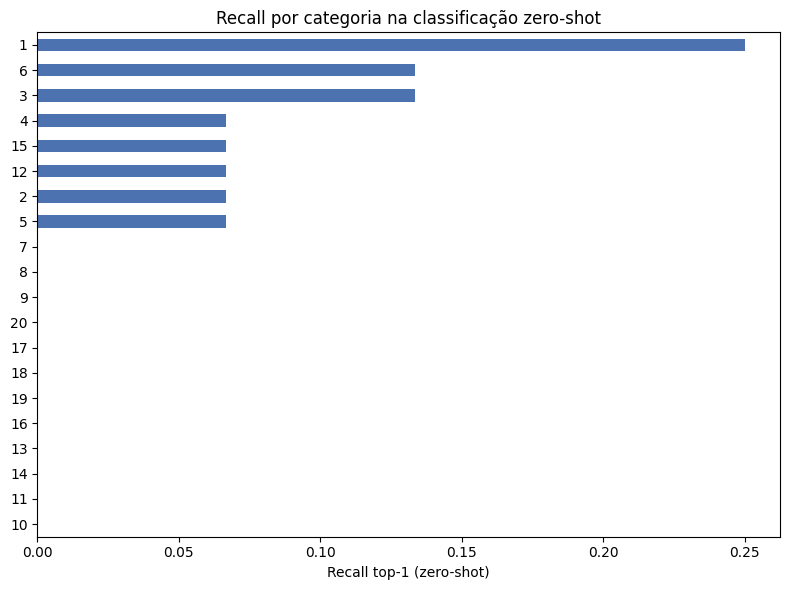

In [21]:
category_names = sorted(ads_df["category"].unique())

if len(category_names) >= 5:
    category_prompts = [
        f"an advertisement for {name.replace('_', ' ').replace('-', ' ')}" for name in category_names
    ]
    category_embeddings = encode_texts(category_prompts)

    similarity = ads_embeddings @ category_embeddings.T
    true_index = torch.tensor([category_names.index(c) for c in ads_df["category"]])
    predicted_index = similarity.argmax(dim=1)

    top1 = (predicted_index == true_index).float().mean().item()
    top3 = (similarity.topk(3, dim=1).indices == true_index[:, None]).any(dim=1).float().mean().item()

    own_scores = similarity[torch.arange(len(true_index)), true_index]
    other_mask = torch.ones_like(similarity, dtype=torch.bool)
    other_mask[torch.arange(len(true_index)), true_index] = False
    other_scores = similarity[other_mask]

    print(f"Classificação zero-shot por categoria de produto ({len(category_names)} categorias, sem nenhum treino)")
    print(f"  Acurácia top-1: {top1:.1%}  (acaso: {1 / len(category_names):.1%})")
    print(f"  Acurácia top-3: {top3:.1%}")
    print(f"  Cosseno médio com a própria categoria: {own_scores.mean().item():.4f}")
    print(f"  Cosseno médio com as outras categorias: {other_scores.mean().item():.4f}")

    recall_by_category = pd.Series(
        (predicted_index == true_index).float().numpy(), index=ads_df["category"].values
    ).groupby(level=0).mean().sort_values()

    recall_by_category.plot(kind="barh", figsize=(8, 6), color="#4C72B0")
    plt.xlabel("Recall top-1 (zero-shot)")
    plt.title("Recall por categoria na classificação zero-shot")
    plt.tight_layout()
    plt.show()
else:
    print("As categorias de produto não estão disponíveis na estrutura de pastas do corpus.")

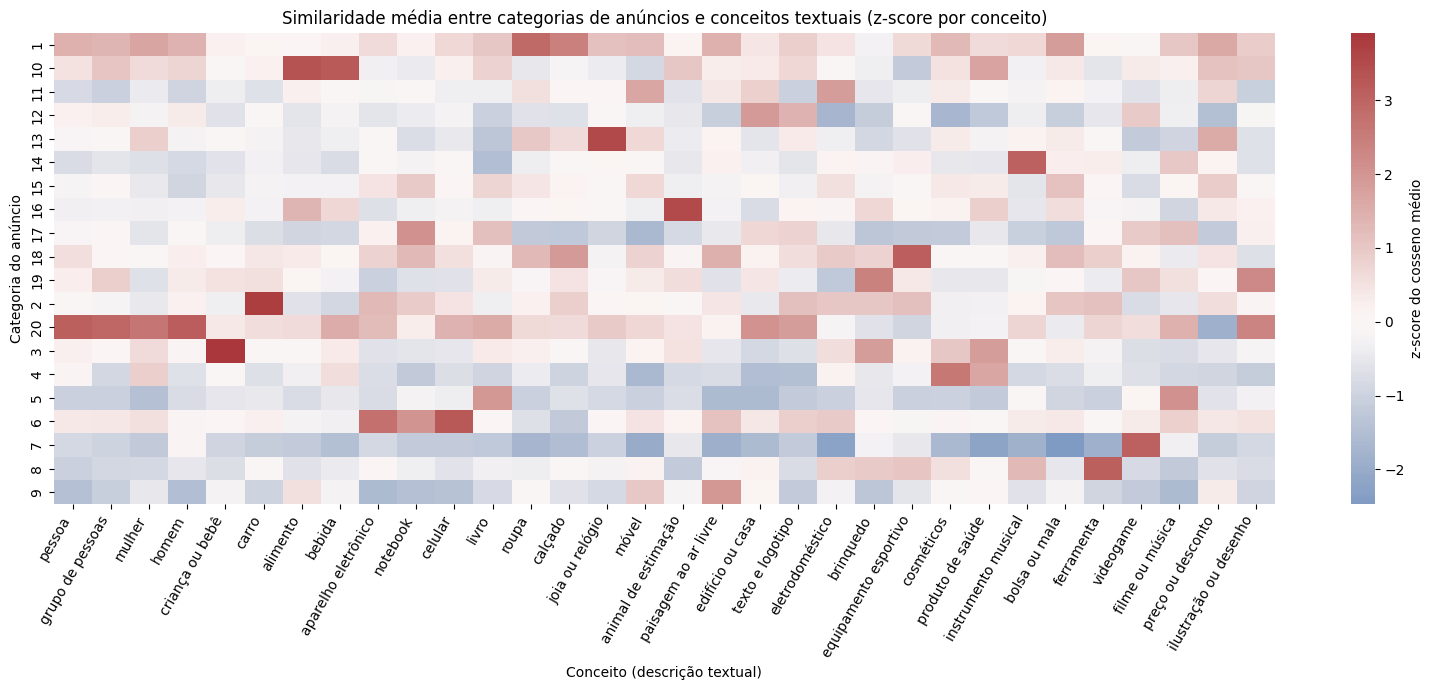

In [22]:
category_concept = pd.DataFrame(scores_ads.numpy(), columns=OBJECT_LABELS)
category_concept = category_concept.groupby(ads_df["category"].values).mean()
category_concept_z = (category_concept - category_concept.mean()) / category_concept.std()

plt.figure(figsize=(16, 7))
sns.heatmap(category_concept_z, cmap="vlag", center=0, cbar_kws={"label": "z-score do cosseno médio"})
plt.xlabel("Conceito (descrição textual)")
plt.ylabel("Categoria do anúncio")
plt.title("Similaridade média entre categorias de anúncios e conceitos textuais (z-score por conceito)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

In [23]:
def mean_off_diagonal(matrix):
    n = matrix.shape[0]
    return ((matrix.sum() - matrix.diagonal().sum()) / (n * (n - 1))).item()


image_image = mean_off_diagonal(ads_embeddings @ ads_embeddings.T)
text_text = mean_off_diagonal(concept_embeddings @ concept_embeddings.T)
image_text = (ads_embeddings @ concept_embeddings.T).mean().item()

print("Cosseno médio entre vetores")
print(f"  imagem-imagem (anúncios):   {image_image:.4f}")
print(f"  texto-texto (conceitos):    {text_text:.4f}")
print(f"  imagem-texto (cross-modal): {image_text:.4f}")

Cosseno médio entre vetores
  imagem-imagem (anúncios):   0.4799
  texto-texto (conceitos):    0.8641
  imagem-texto (cross-modal): 0.2096


### Análise do alinhamento no ADS-16

**Zero-shot por categoria: resultado esperado e explicação.** A acurácia top-1 foi de 4,3% (acaso: 5,0%) e o cosseno médio com a categoria correta (0,2243) é idêntico ao cosseno com as demais (0,2243). Esse resultado **não indica falha do CLIP**: no dataset, as 20 categorias são identificadas apenas por números ("1" a "20"), e o prompt "an advertisement for 7" não carrega informação semântica alguma; o modelo não tem como ligar o texto à imagem. O experimento mostra que a classificação zero-shot depende de nomes de classe significativos.

**O CLIP, porém, separa as categorias.** O mapa de calor (z-score do cosseno médio por conceito) mostra que cada categoria numérica tem um perfil semântico próprio, coerente com o que a busca da atividade 2.2 já tinha mostrado: a categoria **2** se alinha a *carro* (autopeças), a **3** a *criança ou bebê*, a **8** a *ferramenta*, a **10** a *alimento* e *bebida*, a **13** a *joia ou relógio*, a **16** a *animal de estimação* e a **20** a *pessoa*, *mulher* e *homem* (sites de encontro). Isso sugere um caminho para tornar o zero-shot viável: nomear cada categoria pelo conceito dominante do seu perfil (ou usar nomes reais, se o dataset os fornecesse).

**Geometria do espaço de embeddings.** O cosseno médio imagem-imagem é 0,48 e o texto-texto é 0,86, enquanto o imagem-texto é 0,21. Os vetores de texto ficam muito mais próximos entre si do que os de imagem, e o par cross-modal é baixo: é o *modality gap* do CLIP, em que imagens e textos ocupam regiões diferentes (cones) do mesmo espaço. É por isso que os cossenos absolutos são baixos (≈0,2 a 0,3) mesmo para boas correspondências e que o threshold da atividade 2.1 foi definido de forma relativa (μ + 1σ).

## Comparação: Consulta Textual do CLIP vs. Tokenização do BERT

Nas buscas acima, a consulta passa pelo tokenizador do CLIP e pelo encoder de texto, e o resultado é **um único vetor** de 512 dimensões, comparado por cosseno a vetores de imagem. No BERT, a tokenização serve a outro propósito: produzir uma sequência de vetores contextuais (um por token) para tarefas de linguagem. As diferenças relevantes para padding e *attention mask* são:

- **Padding.** Os modelos operam em lotes de tamanho fixo. Sequências mais curtas que o comprimento do lote recebem tokens de preenchimento (`[PAD]` no BERT; no CLIP, o token de preenchimento do tokenizador, que é o mesmo `<|endoftext|>`). O comprimento máximo é 77 tokens no CLIP e 512 no BERT.
- **Attention mask.** É um vetor de 1 (token real) e 0 (preenchimento) que o modelo usa para somar um valor muito negativo aos scores de atenção das posições de padding, fazendo o softmax atribuir peso zero a elas. No **BERT**, a atenção é bidirecional: cada token vê todos os outros. Sem a máscara, os `[PAD]` entram no cálculo de todos os tokens, inclusive do `[CLS]`, e o vetor da frase muda. No **CLIP**, o encoder de texto usa atenção causal (cada token só vê os anteriores) e o vetor da consulta é lido na posição do token final `<|endoftext|>`. O preenchimento vem depois desse token, então não consegue influenciar o resultado mesmo sem a máscara, que fica útil para ignorar essas posições nos demais cálculos.

As células a seguir mostram a tokenização lado a lado e medem esse efeito.

In [24]:
from transformers import AutoTokenizer, BertModel

BERT_NAME = "bert-base-uncased"

clip_tokenizer = processor.tokenizer
bert_tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)

query = "a woman holding a smartphone"

clip_encoding = clip_tokenizer(query, padding="max_length", max_length=14, return_tensors="pt")
bert_encoding = bert_tokenizer(query, padding="max_length", max_length=14, return_tensors="pt")


def encoding_table(tokenizer, encoding):
    ids = encoding["input_ids"][0].tolist()
    return pd.DataFrame({
        "posição": range(len(ids)),
        "token": tokenizer.convert_ids_to_tokens(ids),
        "id": ids,
        "attention_mask": encoding["attention_mask"][0].tolist(),
    })


print(f"CLIP: vocabulário {clip_tokenizer.vocab_size}, contexto máximo {clip_tokenizer.model_max_length}, token de padding {clip_tokenizer.pad_token}")
display(encoding_table(clip_tokenizer, clip_encoding))

print(f"BERT: vocabulário {bert_tokenizer.vocab_size}, contexto máximo {bert_tokenizer.model_max_length}, token de padding {bert_tokenizer.pad_token}")
display(encoding_table(bert_tokenizer, bert_encoding))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

CLIP: vocabulário 49408, contexto máximo 77, token de padding <|endoftext|>


,posição,token,id,attention_mask
0,0,<|startoftext|>,49406,1
1,1,a</w>,320,1
2,2,woman</w>,2308,1
3,3,holding</w>,5050,1
4,4,a</w>,320,1
5,5,smartphone</w>,11290,1
6,6,<|endoftext|>,49407,1
7,7,<|endoftext|>,49407,0
8,8,<|endoftext|>,49407,0
9,9,<|endoftext|>,49407,0


BERT: vocabulário 30522, contexto máximo 512, token de padding [PAD]


,posição,token,id,attention_mask
0,0,[CLS],101,1
1,1,a,1037,1
2,2,woman,2450,1
3,3,holding,3173,1
4,4,a,1037,1
5,5,smartphone,26381,1
6,6,[SEP],102,1
7,7,[PAD],0,0
8,8,[PAD],0,0
9,9,[PAD],0,0


In [25]:
bert_model = BertModel.from_pretrained(BERT_NAME).to(device)
bert_model.eval()

bert_short = bert_tokenizer(query, return_tensors="pt").to(device)
bert_padded = bert_tokenizer(query, padding="max_length", max_length=32, return_tensors="pt").to(device)
bert_padded_without_mask = {k: v for k, v in bert_padded.items() if k != "attention_mask"}

with torch.no_grad():
    cls_short = bert_model(**bert_short).last_hidden_state[:, 0]
    cls_padded_masked = bert_model(**bert_padded).last_hidden_state[:, 0]
    cls_padded_unmasked = bert_model(**bert_padded_without_mask).last_hidden_state[:, 0]

print("BERT: cosseno do vetor [CLS] em relação à frase sem padding")
print(f"  com padding e com attention_mask: {F.cosine_similarity(cls_short, cls_padded_masked).item():.6f}")
print(f"  com padding e sem attention_mask: {F.cosine_similarity(cls_short, cls_padded_unmasked).item():.6f}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT: cosseno do vetor [CLS] em relação à frase sem padding
  com padding e com attention_mask: 1.000000
  com padding e sem attention_mask: 0.627402


In [26]:
@torch.no_grad()
def clip_query_embedding(inputs):
    output = model.get_text_features(**inputs)
    features = to_feature_tensor(output, ("text_embeds", "pooler_output"))
    if features.shape[-1] != model.config.projection_dim:
        features = model.text_projection(features)
    return F.normalize(features, dim=-1)


clip_plain = processor(text=[query], return_tensors="pt", padding=False).to(device)
clip_padded = processor(text=[query], return_tensors="pt", padding="max_length", max_length=77).to(device)
clip_padded_without_mask = {"input_ids": clip_padded["input_ids"]}

embedding_plain = clip_query_embedding(clip_plain)
embedding_padded_masked = clip_query_embedding(clip_padded)
embedding_padded_unmasked = clip_query_embedding(clip_padded_without_mask)

print("CLIP: cosseno do embedding da consulta em relação à frase sem padding")
print(f"  com padding até 77 e com attention_mask: {F.cosine_similarity(embedding_plain, embedding_padded_masked).item():.6f}")
print(f"  com padding até 77 e sem attention_mask: {F.cosine_similarity(embedding_plain, embedding_padded_unmasked).item():.6f}")

CLIP: cosseno do embedding da consulta em relação à frase sem padding
  com padding até 77 e com attention_mask: 1.000000
  com padding até 77 e sem attention_mask: 1.000000


### Síntese da comparação

| Aspecto | CLIP (encoder de texto) | BERT |
|---|---|---|
| Tokenizador | BPE em nível de byte, texto em minúsculas | WordPiece (`bert-base-uncased`, minúsculas) |
| Tokens especiais | `<\|startoftext\|>` e `<\|endoftext\|>` | `[CLS]` no início e `[SEP]` no fim |
| Contexto máximo | 77 tokens | 512 tokens |
| Atenção | causal: cada token vê só os anteriores | bidirecional: cada token vê todos |
| Vetor usado | estado na posição de `<\|endoftext\|>`, projetado para 512 dimensões | `[CLS]` ou todos os tokens, conforme a tarefa |
| Objetivo de pré-treinamento | contrastivo imagem-texto | máscara de tokens (MLM) e próxima sentença (NSP) |
| Efeito do padding sem `attention_mask` | praticamente nenhum no vetor final (padding fica depois do token final e a atenção é causal) | altera todos os vetores, inclusive o `[CLS]` |

Na busca semântica, o que importa é que a consulta vire um ponto no mesmo espaço das imagens: o texto é codificado em um vetor único e comparado por cosseno. A tokenização do BERT, por outro lado, prepara uma sequência de vetores contextuais para tarefas em que cada token importa, e por isso o controle de padding por `attention_mask` é indispensável.

**Resultado do experimento.** No BERT, tirar a `attention_mask` com padding mudou o vetor `[CLS]` (cosseno 0,627 em relação à frase sem padding), pois a atenção bidirecional faz o padding contaminar todos os tokens. No CLIP, o resultado foi idêntico (1,000) mesmo sem máscara, porque a atenção é causal e o vetor vem do token `<|endoftext|>`, que não enxerga o padding posterior. Na prática, o `attention_mask` é indispensável no BERT, enquanto no CLIP o padding à direita é inofensivo.

### Conclusões e limitações da atividade 2

- O CLIP permitiu ranquear objetos e buscar imagens por linguagem natural, **sem treinar nenhum modelo**, com resultados bons em temas fortes do corpus (promoção, comida, luxo, texto) e fracos em composições específicas (cena com vários atributos) e em conceitos ausentes do corpus.
- O corpus principal tem **301 anúncios únicos** (o dataset documenta 300 e 20 categorias, e não as 16 do enunciado). O mínimo de 500 imagens foi atendido pelo corpus estendido (1.501, com fotos pessoais) no ranking 2.1.
- Os resultados dependem da lista de conceitos, do threshold relativo e dos *templates* de prompt (usamos um ensemble de três). Não há rótulos de referência para os objetos, então a avaliação é qualitativa (inspeção das imagens recuperadas).
- Este notebook foi executado em CPU; a indexação das 1.501 imagens levou 393,7 s. Em GPU T4 esse passo é mais rápido.

## Referências

- Roffo, G.; Vinciarelli, A. (2016). *Personality in Computational Advertising: A Benchmark*. International Workshop on Emotions and Personality in Personalized Systems (EMPIRE 2016), ACM RecSys. http://ceur-ws.org/Vol-1680/
- Radford, A. et al. (2021). *Learning Transferable Visual Models From Natural Language Supervision*. ICML 2021. https://arxiv.org/abs/2103.00020
- Devlin, J. et al. (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*. NAACL-HLT 2019. https://arxiv.org/abs/1810.04805
- Wolf, T. et al. (2020). *Transformers: State-of-the-Art Natural Language Processing*. EMNLP 2020 (System Demonstrations). https://arxiv.org/abs/1910.03771

## Declaração de uso de ferramentas de IA

Este notebook foi desenvolvido com apoio do assistente de IA Claude (Anthropic), utilizado para estruturar o código e redigir os textos de análise.